## Problem 19
Manual edge detection using Sobel, Prewitt, and Canny operators.

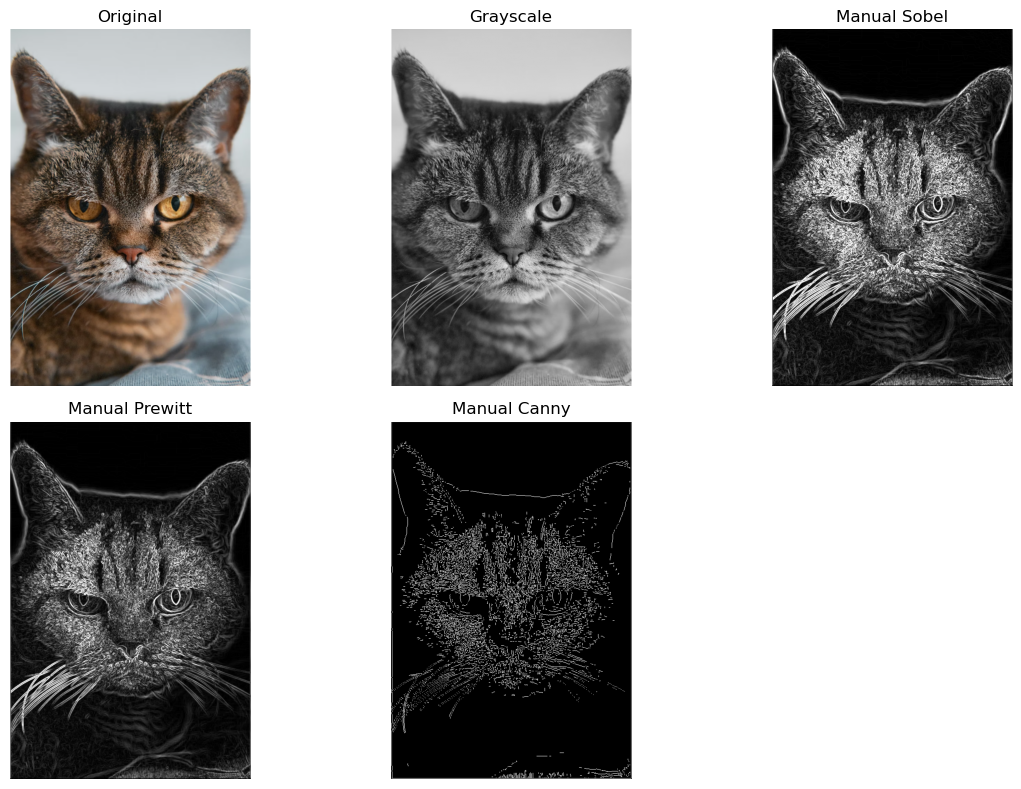

In [ ]:
import cv2
import math
import matplotlib.pyplot as plt
import numpy as np

source = cv2.imread("cat.png")
height, width = source.shape[:2]
gray = np.zeros((height, width), dtype=float)
for row in range(height):
    for col in range(width):
        blue = int(source[row, col, 0])
        green = int(source[row, col, 1])
        red = int(source[row, col, 2])
        gray[row, col] = 0.114 * blue + 0.587 * green + 0.299 * red

sobel_x = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
sobel_y = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
prewitt_x = [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]]
prewitt_y = [[-1, -1, -1], [0, 0, 0], [1, 1, 1]]

def gradients(image, kernel_x, kernel_y):
    gx = np.zeros(image.shape, dtype=float)
    gy = np.zeros(image.shape, dtype=float)
    for row in range(1, height - 1):
        for col in range(1, width - 1):
            for kr in range(3):
                for kc in range(3):
                    value = image[row + kr - 1, col + kc - 1]
                    gx[row, col] += value * kernel_x[kr][kc]
                    gy[row, col] += value * kernel_y[kr][kc]
    return gx, gy

def magnitude(gx, gy):
    result = np.zeros(gx.shape, dtype=np.uint8)
    for row in range(height):
        for col in range(width):
            value = math.sqrt(gx[row, col] ** 2 + gy[row, col] ** 2)
            result[row, col] = 255 if value > 255 else int(value)
    return result

sobel_gx, sobel_gy = gradients(gray, sobel_x, sobel_y)
prewitt_gx, prewitt_gy = gradients(gray, prewitt_x, prewitt_y)
sobel_edges = magnitude(sobel_gx, sobel_gy)
prewitt_edges = magnitude(prewitt_gx, prewitt_gy)

# Manual Canny: blur, Sobel gradient, non-maximum suppression, and hysteresis.
blur = np.zeros(gray.shape, dtype=float)
gaussian = [[1, 2, 1], [2, 4, 2], [1, 2, 1]]
for row in range(1, height - 1):
    for col in range(1, width - 1):
        total = 0
        for kr in range(3):
            for kc in range(3):
                total += gray[row + kr - 1, col + kc - 1] * gaussian[kr][kc]
        blur[row, col] = total / 16

gx, gy = gradients(blur, sobel_x, sobel_y)
strength = np.zeros(gray.shape, dtype=float)
angle = np.zeros(gray.shape, dtype=float)
for row in range(height):
    for col in range(width):
        strength[row, col] = math.sqrt(gx[row, col] ** 2 + gy[row, col] ** 2)
        angle[row, col] = math.degrees(math.atan2(gy[row, col], gx[row, col]))

thin = np.zeros(gray.shape, dtype=float)
for row in range(1, height - 1):
    for col in range(1, width - 1):
        direction = angle[row, col]
        if direction < 0: direction += 180
        if direction < 22.5 or direction >= 157.5:
            first, second = strength[row, col - 1], strength[row, col + 1]
        elif direction < 67.5:
            first, second = strength[row - 1, col + 1], strength[row + 1, col - 1]
        elif direction < 112.5:
            first, second = strength[row - 1, col], strength[row + 1, col]
        else:
            first, second = strength[row - 1, col - 1], strength[row + 1, col + 1]
        if strength[row, col] >= first and strength[row, col] >= second:
            thin[row, col] = strength[row, col]

low_threshold = 40
high_threshold = 100
canny = np.zeros(gray.shape, dtype=np.uint8)
for row in range(1, height - 1):
    for col in range(1, width - 1):
        if thin[row, col] >= high_threshold:
            canny[row, col] = 255
        elif thin[row, col] >= low_threshold:
            for nr in range(row - 1, row + 2):
                for nc in range(col - 1, col + 2):
                    if thin[nr, nc] >= high_threshold:
                        canny[row, col] = 255

plt.figure(figsize=(12, 8))
plt.subplot(2, 3, 1)
plt.imshow(source[:, :, ::-1])
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(sobel_edges, cmap="gray")
plt.title("Manual Sobel")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(prewitt_edges, cmap="gray")
plt.title("Manual Prewitt")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(canny, cmap="gray")
plt.title("Manual Canny")
plt.axis("off")
plt.tight_layout()
plt.show()
